# Assignment 6: NLP Web Scraping, Text Preprocessing & Word Frequency Analysis
**Author:** Kristian Hudák  
**Course:** AI Olympiad (OAI) Preparation Course

This project implements an end-to-end NLP data extraction and cleaning pipeline using `BeautifulSoup`, regular expressions, and `NLTK` on Project Gutenberg literature:
1. Web scraping and HTML parsing of full-text literature
2. Punctuation removal, regex sanitization, and text normalization
3. Tokenization and case conversion
4. Stopword elimination and frequency distribution analysis (`FreqDist`)
5. Visualizing the top 20 most frequent terms


### Step 1: HTML Scraping, Parsing & Punctuation Cleaning
Extracting text from Project Gutenberg using `requests` and `BeautifulSoup`, followed by regex sanitization to remove punctuation.


In [ ]:
from bs4 import BeautifulSoup
import requests
import re

url = "https://www.gutenberg.org/cache/epub/164/pg164-images.html"
response = requests.get(url,verify=False)
response.raise_for_status()
h_rights = response.text

soup = BeautifulSoup(h_rights, "html.parser")
clean_text = soup.get_text(separator="\n", strip=True)
clean_text = re.sub("[“ ,.?!:;”’]", " ", clean_text)


print(clean_text)


/usr/local/lib/python3.12/dist-packages/urllib3/connectionpool.py:1097: InsecureRequestWarning: Unverified HTTPS request is being made to host 'www.gutenberg.org'. Adding certificate verification is strongly advised. See: https://urllib3.readthedocs.io/en/latest/advanced-usage.html#tls-warnings
  warnings.warn(


Twenty Thousand Leagues under the Sea | Project Gutenberg
The Project Gutenberg eBook of
Twenty Thousand Leagues under the Sea
This ebook is for the use of anyone anywhere in the United States and
most other parts of the world at no cost and with almost no restrictions
whatsoever  You may copy it  give it away or re-use it under the terms
of the Project Gutenberg License included with this ebook or online
at
www gutenberg org
  If you are not located in the United States 
you will have to check the laws of the country where you are located
before using this eBook 
Title
  Twenty Thousand Leagues under the Sea
Author
  Jules Verne
Release date
  September 1  1994 [eBook #164]
Most recently updated  March 18  2025
Language
  English
Credits
  a number of anonymous Gutenberg Project volunteers
*** START OF THE PROJECT GUTENBERG EBOOK TWENTY THOUSAND LEAGUES UNDER THE SEA ***
Twenty Thousand Leagues under the Sea
by Jules Verne
Contents
PART I
CHAPTER I A SHIFTING REEF
CHAPTER II PRO AND C

In [ ]:
import nltk
nltk.download('punkt')
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

### Step 2: NLTK Tokenization & Case Normalization
Tokenizing the cleaned text into individual word tokens and converting all words to lowercase.


In [ ]:
from nltk.tokenize import word_tokenize
words = word_tokenize(clean_text)

In [ ]:
lower_words = [w.lower() for w in words]
lower_words[:15]


['twenty',
 'thousand',
 'leagues',
 'under',
 'the',
 'sea',
 '|',
 'project',
 'gutenberg',
 'the',
 'project',
 'gutenberg',
 'ebook',
 'of',
 'twenty']

In [ ]:
words
print(len(words))

108525


### Step 3: Stopword Filtering & Frequency Distribution Calculation
Filtering out English stopwords using NLTK's standard corpus and computing word frequencies using `FreqDist`.


In [ ]:
from nltk.probability import FreqDist

FreqDist(['a','a','b','b','b','b','b','c'])
frequentation = FreqDist(lower_words)
frequentation
#frequentation.most_common(5)

FreqDist({'the': 8758, 'of': 4225, 'and': 2672, 'to': 2591, 'i': 2189, 'a': 2151, 'in': 1635, 'was': 1342, 'it': 1305, 'that': 1042, ...})

In [ ]:
from nltk.corpus import stopwords
nltk.download('stopwords')

sw = set(stopwords.words('english'))
new_words = []

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


True

In [ ]:
for w in lower_words:
  if w not in sw: new_words.append(w)

In [ ]:
frequentation = FreqDist(new_words)
frequentation.most_common(10)

### Step 4: Visualizing Top 20 Word Frequency Distribution


<Axes: xlabel='Samples', ylabel='Counts'>

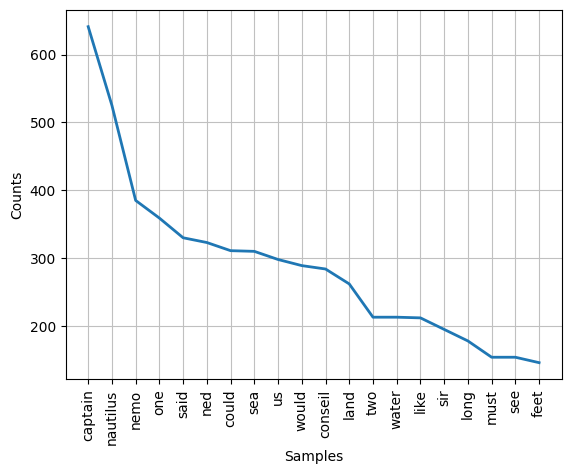

In [ ]:
frequentation.plot(20,cumulative= False)